# Super-Convergence (Smith & Topin, 2017): воспроизведение экспериментов

In [1]:
import os, json, time, math, hashlib
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

DEBUG = False
HOURS = 8
SCALE = None
ARCH = 'resnet56'
SEEDS = [0]

BUDGETS = [2000, 6000, 10000]
MAX_LRS = [1.0, 3.0]
LIMITED = [10000, 50000]
WDS = [1e-3, 1e-4, 1e-5]

RUN = dict(
    range_test=True,
    main=True,
    budgets=True,
    max_lr=True,
    lr_estimate=True,
    limited_data=True,
    weight_decay=True,
    bn_maf=True,
    mnist=True,
    depth=False,
    batch_size=False,
    momentum=False,
    dropout=False,
    adaptive=False,
    sgdr=False,
    cifar100=False,
    wide_resnet=False,
    densenet=False,
)

dev = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
ADEV = 'cuda' if dev == 'cuda' else 'cpu'
AMP = dev == 'cuda'
torch.backends.cudnn.benchmark = True

ROOT = 'sc_runs'
DATA_DIR = f'{ROOT}/data'
CACHE = f'{ROOT}/cache' + ('_debug' if DEBUG else '')
FIGS = f'{ROOT}/figures' + ('_debug' if DEBUG else '')
for d in (DATA_DIR, CACHE, FIGS):
    os.makedirs(d, exist_ok=True)
print(dev, '| DEBUG =', DEBUG)

cuda | DEBUG = False


## Данные

In [2]:
DATA = {}

def get_data(name):
    if name in DATA:
        return DATA[name]
    DATA.clear()
    cls = dict(cifar10=torchvision.datasets.CIFAR10, cifar100=torchvision.datasets.CIFAR100,
               mnist=torchvision.datasets.MNIST)[name]
    out = []
    for train in (True, False):
        ds = cls(DATA_DIR, train=train, download=True)
        x = torch.as_tensor(np.asarray(ds.data)).float().div(255)
        x = x[:, None] if x.ndim == 3 else x.permute(0, 3, 1, 2)
        out += [x, torch.as_tensor(np.asarray(ds.targets)).long()]
    xtr, ytr, xte, yte = out
    if DEBUG:
        xtr, ytr, xte, yte = xtr[:2000], ytr[:2000], xte[:500], yte[:500]
    mean, std = xtr.mean((0, 2, 3), keepdim=True), xtr.std((0, 2, 3), keepdim=True)
    DATA[name] = [t.to(dev) for t in ((xtr - mean) / std, ytr, (xte - mean) / std, yte)]
    return DATA[name]

def augment(x):
    n = len(x)
    x = torch.where(torch.rand(n, 1, 1, 1, device=x.device) < 0.5, x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4), mode='reflect')
    ar = torch.arange(32, device=x.device)
    r = torch.randint(0, 9, (n, 1), device=x.device) + ar
    c = torch.randint(0, 9, (n, 1), device=x.device) + ar
    return xp[torch.arange(n, device=x.device)[:, None, None], :, r[:, :, None], c[:, None, :]].permute(0, 3, 1, 2)

## Модели

In [3]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.b2 = nn.BatchNorm2d(cout)
        self.stride, self.pad = stride, cout - cin

    def forward(self, x):
        y = self.b2(self.c2(F.relu(self.b1(self.c1(x)))))
        if self.stride > 1:
            x = F.avg_pool2d(x, 3, self.stride, ceil_mode=True)
        if self.pad:
            x = F.pad(x, (0, 0, 0, 0, 0, self.pad))
        return F.relu(y + x)

class ResNet(nn.Module):
    def __init__(self, depth, n_classes=10, widths=(16, 32, 64), drop=0.):
        super().__init__()
        n, cin = (depth - 2) // 6, widths[0]
        layers = [nn.Conv2d(3, cin, 3, 1, 1, bias=False), nn.BatchNorm2d(cin), nn.ReLU()]
        for s, w in enumerate(widths):
            for j in range(n):
                layers.append(Block(cin, w, 2 if s > 0 and j == 0 else 1))
                cin = w
        self.body, self.drop, self.fc = nn.Sequential(*layers), nn.Dropout(drop), nn.Linear(cin, n_classes)

    def forward(self, x):
        return self.fc(self.drop(F.adaptive_avg_pool2d(self.body(x), 1).flatten(1)))

class DenseLayer(nn.Module):
    def __init__(self, cin, k):
        super().__init__()
        self.bn, self.conv = nn.BatchNorm2d(cin), nn.Conv2d(cin, k, 3, 1, 1, bias=False)

    def forward(self, x):
        return torch.cat([x, self.conv(F.relu(self.bn(x)))], 1)

def densenet(depth=40, k=12, n_classes=10):
    n, c = (depth - 4) // 3, 16
    layers = [nn.Conv2d(3, c, 3, 1, 1, bias=False)]
    for blk in range(3):
        for _ in range(n):
            layers.append(DenseLayer(c, k)); c += k
        if blk < 2:
            layers += [nn.BatchNorm2d(c), nn.ReLU(), nn.Conv2d(c, c, 1, bias=False), nn.AvgPool2d(2)]
    return nn.Sequential(*layers, nn.BatchNorm2d(c), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, n_classes))

def lenet(n_classes=10):
    return nn.Sequential(nn.Conv2d(1, 20, 5), nn.MaxPool2d(2), nn.Conv2d(20, 50, 5), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(800, 500), nn.ReLU(), nn.Linear(500, n_classes))

def make_model(arch, n_classes, drop=0.):
    if arch.startswith('resnet'):
        m = ResNet(int(arch[6:]), n_classes, drop=drop)
    elif arch == 'wrn32':
        m = ResNet(32, n_classes, widths=(16, 64, 256), drop=drop)
    elif arch == 'densenet40':
        m = densenet(40, 12, n_classes)
    else:
        m = lenet(n_classes)
    for mod in m.modules():
        if isinstance(mod, nn.Conv2d):
            nn.init.kaiming_normal_(mod.weight, mode='fan_out', nonlinearity='relu')
    return m.to(dev).to(memory_format=torch.channels_last)

for a in ['resnet20', 'resnet56', 'resnet110', 'wrn32', 'densenet40']:
    print(f'{a:11s}', f"{sum(p.numel() for p in make_model(a, 10).parameters()) / 1e6:.2f}M параметров")

resnet20    0.27M параметров
resnet56    0.85M параметров
resnet110   1.73M параметров
wrn32       5.83M параметров
densenet40  1.02M параметров


## Расписания learning rate и обучение

In [4]:
def schedule(p, i, iters):
    k, total = p['kind'], p.get('total', iters)
    if k == 'const':
        return p['lr'], 0.
    if k == 'pc':
        return p['lr'] * 0.1 ** sum(i >= f * total for f in p.get('drops', (0.5, 0.75))), 0.
    lo, hi = p['lr']
    if k == 'linear':
        return lo + (hi - lo) * i / total, 0.
    if k == '1cycle':
        cyc = total * (1 - p.get('tail', 0.))
        if i < cyc:
            u = 1 - abs(2 * i / cyc - 1)
            return lo + (hi - lo) * u, u
        return lo * 1e-3 ** ((i - cyc) / max(1, total - cyc)), 0.
    if k == 'sgdr':
        T, start = total / 7, 0.
        for L in (T, 2 * T, 4 * T):
            if i < start + L:
                break
            start += L
        return lo + (hi - lo) * (1 + math.cos(math.pi * min(1., (i - start) / L))) / 2, 0.
    raise ValueError(k)

def maf_for(iters):
    return float(np.interp(iters, [2000, 4000, 6000, 8000, 10000, 20000], [.80, .85, .90, .93, .95, .97]))

def make_opt(name, params, mom, wd):
    if name in ('sgd', 'nesterov'):
        return torch.optim.SGD(params, lr=0.1, momentum=mom, weight_decay=wd, nesterov=name == 'nesterov')
    return dict(adam=torch.optim.Adam, adagrad=torch.optim.Adagrad, adadelta=torch.optim.Adadelta)[name](params, weight_decay=wd)

def sgd_step(model, opt, scaler, x, y):
    with torch.autocast(ADEV, torch.float16, enabled=AMP):
        loss = F.cross_entropy(model(x), y)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()
    return loss.detach().float()

@torch.no_grad()
def evaluate(model, X, Y):
    model.eval()
    correct, loss = 0, 0.
    for i in range(0, len(X), 1000):
        with torch.autocast(ADEV, torch.float16, enabled=AMP):
            out = model(X[i:i + 1000]).float()
        loss += F.cross_entropy(out, Y[i:i + 1000], reduction='sum').item()
        correct += (out.argmax(1) == Y[i:i + 1000]).sum().item()
    model.train()
    return correct / len(X), loss / len(X)

def train(arch, data, bs, wd, momentum, opt, policy, iters, maf, drop=0., n_train=None, seed=0, n_eval=25, lr_est=0):
    xtr, ytr, xte, yte = get_data(data)
    if DEBUG:
        bs, n_eval = min(bs, 64), min(n_eval, 5)
    n_train = min(n_train or len(xtr), len(xtr))
    idx = torch.randperm(len(xtr), generator=torch.Generator().manual_seed(seed))[:n_train].to(dev)
    X, Y = xtr[idx], ytr[idx]
    bs = min(bs, n_train)
    torch.manual_seed(seed)
    model = make_model(arch, 100 if data == 'cifar100' else 10, drop)
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.momentum = 1 - maf
    cyc_mom = isinstance(momentum, (list, tuple))
    optim = make_opt(opt, model.parameters(), momentum[0] if cyc_mom else momentum, wd)
    scaler = torch.amp.GradScaler(ADEV, enabled=AMP)
    sub = slice(0, min(10000, n_train))
    evals = set(np.linspace(0, iters, n_eval + 1).round().astype(int)[1:].tolist())
    H = dict(it=[], lr=[], train_loss=[], test_loss=[], test_acc=[], train_acc=[])
    est, snaps, ema = [], [], None
    perm, pos, run_loss, run_n, diverged, t0 = torch.randperm(n_train, device=dev), 0, 0., 0, False, time.time()
    model.train()
    for i in range(iters):
        lr, u = schedule(policy, i, iters)
        mom = momentum[0] - (momentum[0] - momentum[1]) * u if cyc_mom else momentum
        for g in optim.param_groups:
            g['lr'] = lr
            if 'momentum' in g:
                g['momentum'] = mom
        if pos + bs > n_train:
            perm, pos = torch.randperm(n_train, device=dev), 0
        b = perm[pos:pos + bs]
        pos += bs
        run_loss += sgd_step(model, optim, scaler, augment(X[b]) if data != 'mnist' else X[b], Y[b])
        run_n += 1
        if lr_est and i % lr_est == 0:
            snaps.append(torch.cat([p.detach().reshape(-1).float() for p in model.parameters()]))
            if len(snaps) == 3:
                t_a, t_b, t_c = snaps
                snaps.pop(0)
                e = (lr * (t_b - t_a).abs().sum() / (2 * t_b - t_a - t_c).abs().sum()).item()
                ema = e if ema is None else 0.1 * e + 0.9 * ema
                est.append((i, ema, lr))
        if i + 1 in evals:
            tl = (run_loss / run_n).item()
            run_loss, run_n = 0., 0
            te_acc, te_loss = evaluate(model, xte, yte)
            tr_acc, _ = evaluate(model, X[sub], Y[sub])
            for k, v in zip(H, (i + 1, lr, tl, te_loss, te_acc, tr_acc)):
                H[k].append(v)
            if not math.isfinite(tl):
                diverged = True
                break
    return dict(hist=H, est=est, diverged=diverged, time=time.time() - t0, final_test=H['test_acc'][-1],
                best_test=max(H['test_acc']), final_train=H['train_acc'][-1])

## Запуск экспериментов и проверка утверждений

In [5]:
def cache_path(spec, seed):
    key = json.dumps({**spec, 'seed': seed}, sort_keys=True, default=str)
    return f'{CACHE}/{hashlib.md5(key.encode()).hexdigest()[:16]}.json'

def run(spec, seed=0):
    path = cache_path(spec, seed)
    if os.path.exists(path):
        return json.load(open(path))
    try:
        res = train(seed=seed, **spec)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print('   не хватило памяти GPU, запуск пропущен')
        return None
    res.update(spec=spec, seed=seed)
    json.dump(res, open(path, 'w'))
    return res

def R(label, spec):
    rs = [r for r in (run(spec, s) for s in SEEDS) if r]
    if rs:
        f = [100 * r['final_test'] for r in rs]
        print(f"   {str(label):34s} test acc {np.mean(f):6.2f}" + (f" ± {np.std(f):.2f}" if len(f) > 1 else '')
              + ('  (разошлось)' if any(r['diverged'] for r in rs) else '') + f"   [{sum(r['time'] for r in rs) / 60:.1f} мин]")
    return rs

def acc(rs, key='final_test'):
    return 100 * np.mean([r[key] for r in rs]) if rs else float('nan')

def curve(rs, k='test_acc', x='it'):
    h = rs[0]['hist']
    ys = [r['hist'][k] for r in rs if len(r['hist'][k]) == len(h[k])]
    return np.array(h[x]), np.mean(ys, 0) * (100 if 'acc' in k else 1)

def save(name):
    plt.tight_layout()
    plt.savefig(f'{FIGS}/{name}.png', dpi=150)
    plt.show()

CHECKS = {}

def verdict(ours, ref, tol=0.5):
    if not (np.isfinite(ours) and np.isfinite(ref)):
        return '?'
    return '✓' if ours >= ref else '≈' if ours >= ref - tol else '✗'

def check(claim, paper, ours, v):
    CHECKS[claim] = (paper, ours, v)
    print(f' {v}  {claim}\n      статья: {paper} | у нас: {ours}')

ALL = {}

## План экспериментов

In [6]:
def it(n):
    return 20 if DEBUG else max(20, int(n * SCALE))

def base():
    return dict(arch=ARCH, data='cifar10', bs=1000, wd=1e-4, momentum=0.9, opt='sgd')

def PC(lr=0.35, iters=80000, **kw):
    return {**base(), 'policy': dict(kind='pc', lr=lr), 'iters': it(iters), 'maf': 0.999, **kw}

def CLR(lo=0.1, hi=3.0, iters=10000, tail=0., **kw):
    n = it(iters)
    return {**base(), 'policy': dict(kind='1cycle', lr=(lo, hi), tail=tail), 'iters': n, 'maf': maf_for(n), 'lr_est': 10, **kw}

def RT(hi=3.0, iters=5000, **kw):
    n = it(iters)
    return {**base(), 'policy': dict(kind='linear', lr=(0., hi)), 'iters': n, 'maf': maf_for(n), 'n_eval': 50, **kw}

def T2(arch, data, kind, lr, epochs, wd, mom, ss=None):
    n_tr = 60000 if data == 'mnist' else 50000
    n = 20 if DEBUG else max(20, int(epochs * SCALE * n_tr / 512))
    pol = dict(kind='pc', lr=lr) if kind == 'step' else dict(kind='1cycle', lr=lr, tail=1 - 2 * ss / epochs)
    return dict(arch=arch, data=data, bs=512, wd=wd, momentum=mom, opt='sgd', policy=pol, iters=n, maf=maf_for(n))

ADAPT_CAP = dict(adagrad=1.0, adadelta=30.0, adam=0.03)

def build_plan():
    PLAN = {}
    if RUN['range_test']:
        PLAN['range_test'] = {ARCH: RT()}
    if RUN['main']:
        PLAN['main'] = {'PC 0.35': PC(), 'CLR 0.1-3': CLR(), '1cycle 0.1-3 (+хвост 10%)': CLR(tail=0.1)}
    if RUN['budgets']:
        PLAN['budgets'] = {n: CLR(iters=n) for n in BUDGETS}
    if RUN['max_lr']:
        PLAN['max_lr'] = {hi: CLR(hi=hi) for hi in MAX_LRS}
    if RUN['lr_estimate']:
        short = 20 if DEBUG else 300
        PLAN['lr_estimate'] = {
            'const 0.1': {**CLR(), 'policy': dict(kind='const', lr=0.1)},
            'CLR 0.1-3': CLR(),
            'const 0.1, 300 it': {**CLR(), 'policy': dict(kind='const', lr=0.1), 'iters': short, 'lr_est': 1, 'n_eval': 3},
            'CLR 0.1-3, 300 it': {**CLR(), 'policy': dict(kind='1cycle', lr=(0.1, 3.0), total=it(10000)), 'iters': short, 'lr_est': 1, 'n_eval': 3},
        }
    if RUN['limited_data']:
        PLAN['limited_data'] = {}
        for n in LIMITED:
            PLAN['limited_data'][('PC', n)] = PC(**({} if n == 50000 else dict(n_train=n)))
            PLAN['limited_data'][('CLR', n)] = CLR(**({} if n == 50000 else dict(n_train=n)))
    if RUN['depth']:
        PLAN['depth'] = {}
        for a in ['resnet20', 'resnet110']:
            PLAN['depth'].update({('PC', a): PC(arch=a), ('CLR', a): CLR(arch=a, iters=20000), ('RT', a): RT(arch=a)})
    if RUN['batch_size']:
        PLAN['batch_size'] = {bs: CLR(bs=bs) for bs in [256, 512, 1000, 1536]}
    if RUN['momentum']:
        PLAN['momentum'] = {m: CLR(momentum=m) for m in [0.8, 0.85, 0.9, 0.95]}
        PLAN['momentum']['0.95→0.85 (циклический)'] = CLR(momentum=(0.95, 0.85))
    if RUN['weight_decay']:
        PLAN['weight_decay'] = {wd: CLR(wd=wd) for wd in WDS}
    if RUN['bn_maf']:
        PLAN['bn_maf'] = {'MAF 0.999': CLR(maf=0.999), 'MAF по табл. 6': CLR()}
    if RUN['dropout']:
        PLAN['dropout'] = {'CLR': CLR(), 'CLR + dropout 0.2': CLR(drop=0.2), 'RT': RT(), 'RT + dropout 0.2': RT(drop=0.2)}
    if RUN['adaptive']:
        PLAN['adaptive'] = {('PC', 'nesterov'): PC(opt='nesterov'), ('CLR', 'nesterov'): CLR(opt='nesterov')}
        for o, cap in ADAPT_CAP.items():
            PLAN['adaptive'].update({('RT', o): RT(opt=o, hi=cap), ('PC', o): PC(opt=o, lr=cap / 10), ('CLR', o): CLR(opt=o, lo=cap / 30, hi=cap)})
    if RUN['sgdr']:
        PLAN['sgdr'] = {'SGDR 0.1-3': {**CLR(), 'policy': dict(kind='sgdr', lr=(0.1, 3.0))}, 'CLR 0.1-3': CLR()}
    if RUN['cifar100']:
        cm = (0.95, 0.85)
        PLAN['cifar100'] = {'RT': RT(data='cifar100')}
        for e in [100, 200, 400]:
            PLAN['cifar100'][f'step 0.005, {e} эп.'] = T2('resnet56', 'cifar100', 'step', 0.005, e, 1e-4, 0.9)
        PLAN['cifar100']['step 0.1, 100 эп. (наша проверка baseline)'] = T2('resnet56', 'cifar100', 'step', 0.1, 100, 1e-4, 0.9)
        for lo, hi, ss, e in [(0.1, 0.5, 12, 25), (0.1, 0.5, 23, 50), (0.09, 0.9, 45, 100)]:
            PLAN['cifar100'][f'1cycle {lo}-{hi}, {e} эп.'] = T2('resnet56', 'cifar100', '1cycle', (lo, hi), e, 1e-4, cm, ss)
    if RUN['mnist']:
        PLAN['mnist'] = {'step 0.01, 85 эп.': T2('lenet', 'mnist', 'step', 0.01, 85, 5e-4, 0.9)}
        for lo, hi, ss, e in [(0.01, 0.1, 5, 12), (0.01, 0.1, 12, 25), (0.01, 0.1, 23, 50), (0.02, 0.2, 40, 85)]:
            PLAN['mnist'][f'1cycle {lo}-{hi}, {e} эп.'] = T2('lenet', 'mnist', '1cycle', (lo, hi), e, 5e-4, (0.95, 0.8), ss)
    if RUN['wide_resnet']:
        PLAN['wide_resnet'] = {f'step 0.1, {e} эп.': T2('wrn32', 'cifar10', 'step', 0.1, e, 1e-4, 0.9) for e in [100, 200, 400, 800]}
        for lo, hi, ss, e in [(0.1, 0.5, 12, 25), (0.1, 1.0, 23, 50), (0.1, 1.0, 45, 100)]:
            PLAN['wide_resnet'][f'1cycle {lo}-{hi}, {e} эп.'] = T2('wrn32', 'cifar10', '1cycle', (lo, hi), e, 1e-4, (0.95, 0.85), ss)
    if RUN['densenet']:
        PLAN['densenet'] = {f'step 0.1, {e} эп.': T2('densenet40', 'cifar10', 'step', 0.1, e, 1e-4, 0.9) for e in [100, 200, 400]}
        for ss, e in [(22, 50), (34, 75), (45, 100), (70, 150)]:
            PLAN['densenet'][f'1cycle 0.1-4, {e} эп.'] = T2('densenet40', 'cifar10', '1cycle', (0.1, 4.0), e, 1e-6, (0.9, 0.85), ss)
    return PLAN

## Оценка времени

In [7]:
def sync():
    if dev == 'cuda':
        torch.cuda.synchronize()
    elif dev == 'mps':
        torch.mps.synchronize()

def bench(arch, data, bs=128, n=5):
    if DEBUG:
        bs, n = 16, 2
    shape = (1, 28, 28) if data == 'mnist' else (3, 32, 32)
    x, y = torch.randn(bs, *shape, device=dev), torch.randint(0, 10, (bs,), device=dev)
    model = make_model(arch, 100 if data == 'cifar100' else 10)
    opt, scaler = make_opt('sgd', model.parameters(), 0.9, 0.), torch.amp.GradScaler(ADEV, enabled=AMP)
    for k in range(n + 2):
        if k == 2:
            sync(); t = time.time()
        sgd_step(model, opt, scaler, x, y)
    sync()
    return (time.time() - t) / (n * bs)

SPS = {}

def plan_cost(plan):
    out = {}
    for exp, specs in plan.items():
        tr = ev = 0.
        for spec in specs.values():
            key = (spec['arch'], spec['data'])
            if key not in SPS:
                SPS[key] = bench(*key)
            for sd in SEEDS:
                if not os.path.exists(cache_path(spec, sd)):
                    tr += spec['iters'] * spec['bs'] * SPS[key]
                    ev += spec.get('n_eval', 25) * 20000 / 3 * SPS[key]
        out[exp] = (tr, ev)
    return out

if SCALE is None and not DEBUG:
    for ARCH in ['resnet56', 'resnet20']:
        SCALE = 1.0
        c = plan_cost(build_plan())
        tr, ev = sum(v[0] for v in c.values()), sum(v[1] for v in c.values())
        SCALE = min(1.0, max(0.02, (HOURS * 3600 * 0.85 - ev) / tr))
        print(f'{ARCH}: весь план в масштабе статьи ~{(tr + ev) / 3600:.1f} ч -> SCALE = {SCALE:.3f}')
        if SCALE >= 0.15:
            break
    if SCALE < 0.15:
        print('ВНИМАНИЕ: даже с resnet20 обучение получается слишком коротким. Увеличь HOURS или выключи часть экспериментов в RUN.')
SCALE = SCALE or 1.0
PLAN = build_plan()
c = plan_cost(PLAN)
for exp, (tr, ev) in c.items():
    print(f'{exp:14s} ~{(tr + ev) / 3600:5.2f} ч')
print(f'{"ИТОГО":14s} ~{sum(a + b for a, b in c.values()) / 3600:5.2f}')
print(f'\nсеть: {ARCH}, SCALE = {SCALE:.3f}: CLR 10k итераций статьи  {it(10000)} итераций ({it(10000) * 1000 // 50000} эп.), '
      f'PC 80k -> {it(80000)} итераций ({it(80000) * 1000 // 50000} эп.)')

resnet56: весь план в масштабе статьи ~65.9 ч -> SCALE = 0.095
resnet20: весь план в масштабе статьи ~24.2 ч -> SCALE = 0.275
range_test     ~ 0.10 ч
main           ~ 1.70 ч
budgets        ~ 0.33 ч
max_lr         ~ 0.35 ч
lr_estimate    ~ 0.39 ч
limited_data   ~ 3.04 ч
weight_decay   ~ 0.53 ч
bn_maf         ~ 0.35 ч
mnist          ~ 0.03 ч
ИТОГО          ~ 6.83

сеть: resnet20, SCALE = 0.275: CLR 10k итераций статьи  2748 итераций (54 эп.), PC 80k -> 21985 итераций (439 эп.)


нормально нахрен 70 часов))

видюха: rtx 5060 nvidia


## 1. Тест диапазона learning rate
**Гипотезы:** (а) у ResNet-56 точность остаётся высокой при LR вплоть до 3; (б) при росте LR от ~0.3 до ~1.5 train loss растёт, а test loss падает, то есть большой LR регуляризует.

   resnet20                           test acc  74.73   [5.9 мин]


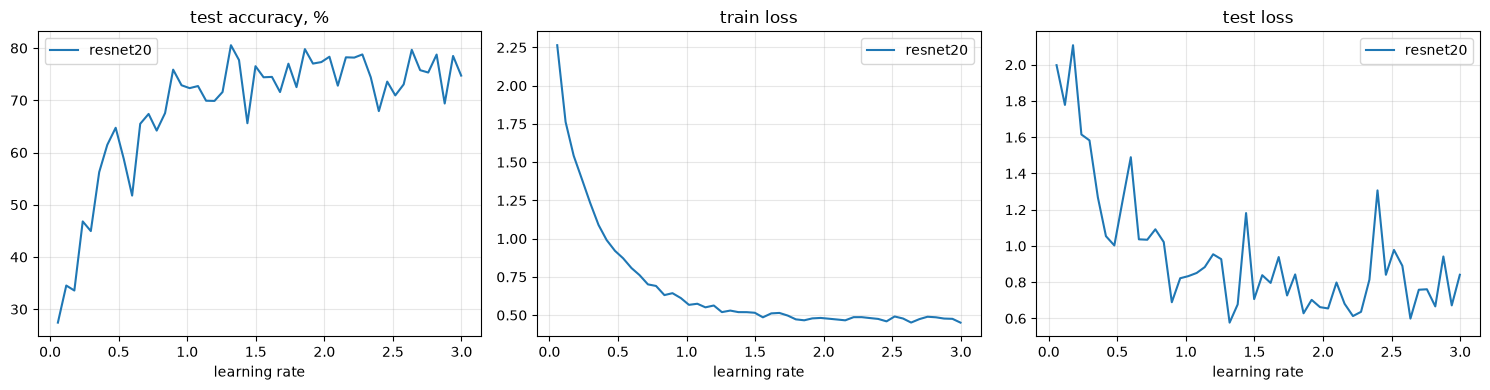

 ≈  resnet20: точность высокая до LR = 3
      статья: рис. 2b, «consistently high» | у нас: пик 80.5%, при LR ≥ 2.5: 75.1%
 ✗  resnet20: большой LR регуляризует (LR 0.3-1.5)
      статья: рис. 8: train loss ↑, test loss ↓ | у нас: наклон train loss -0.453, наклон (test − train) +0.057


In [8]:
def plot_rt(named, name):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for label, rs in named.items():
        if not rs:
            continue
        for a, k in zip(ax, ['test_acc', 'train_loss', 'test_loss']):
            x, y = curve(rs, k, x='lr')
            a.plot(x, y, label=label)
    for a, t in zip(ax, ['test accuracy, %', 'train loss', 'test loss']):
        a.set(xlabel='learning rate', title=t); a.grid(alpha=.3); a.legend()
    save(name)

def rt_checks(rs, name):
    h = rs[0]['hist']
    lr, a = np.array(h['lr']), 100 * np.array(h['test_acc'])
    tr, te = np.array(h['train_loss']), np.array(h['test_loss'])
    hi, peak = a[lr >= 0.83 * lr.max()].mean(), a.max()
    check(f'{name}: точность высокая до LR = 3', 'рис. 2b, «consistently high»',
          f'пик {peak:.1f}%, при LR ≥ 2.5: {hi:.1f}%', verdict(hi, peak - 5, tol=5))
    m = (lr >= 0.3) & (lr <= 1.5)
    if m.sum() >= 3:
        s_tr, s_gap = np.polyfit(lr[m], tr[m], 1)[0], np.polyfit(lr[m], te[m] - tr[m], 1)[0]
        v = '✓' if s_tr > 0 and s_gap < 0 else '≈' if s_gap < 0 else '✗'
        check(f'{name}: большой LR регуляризует (LR 0.3-1.5)', 'рис. 8: train loss ↑, test loss ↓',
              f'наклон train loss {s_tr:+.3f}, наклон (test − train) {s_gap:+.3f}', v)

if 'range_test' in PLAN:
    ALL['range_test'] = {l: R(l, s) for l, s in PLAN['range_test'].items()}
    plot_rt(ALL['range_test'], 'fig2b_range_test')
    rt_checks(ALL['range_test'][ARCH], ARCH)

## 2. Главное сравнение: CLR против обычного обучения
**Гипотеза:** CLR 0.1-3 за 10k итераций даёт точность выше, чем стандартное обучение за 80k (92.4% против 91.2%). Отдельно: «1cycle» (с хвостом, где LR падает ниже минимума) улучшает точность.

   PC 0.35                            test acc  91.56   [90.4 мин]
   CLR 0.1-3                          test acc  91.42   [11.3 мин]
   1cycle 0.1-3 (+хвост 10%)          test acc  91.64   [11.3 мин]


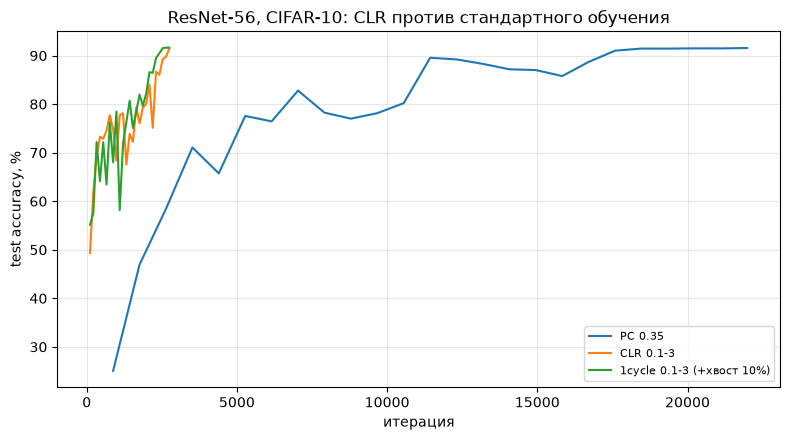

 ≈  Super-convergence: CLR (в 8 раз меньше итераций) не хуже PC
      статья: 92.4% против 91.2% | у нас: 91.4% против 91.6%
 ✓  1cycle с хвостом лучше простого CLR
      статья: «allows an improvement in the accuracy» | у нас: 91.6% против 91.4%


In [9]:
def plot_curves(named, name, title, x='it', xlabel='итерация'):
    plt.figure(figsize=(8, 4.5))
    for label, rs in named.items():
        if rs:
            plt.plot(*curve(rs, x=x), label=str(label))
    plt.xlabel(xlabel); plt.ylabel('test accuracy, %'); plt.title(title)
    plt.ylim(bottom=max(0, plt.ylim()[0])); plt.grid(alpha=.3); plt.legend(fontsize=8)
    save(name)

if 'main' in PLAN:
    ALL['main'] = {l: R(l, s) for l, s in PLAN['main'].items()}
    plot_curves(ALL['main'], 'fig1a_main', 'ResNet-56, CIFAR-10: CLR против стандартного обучения')
    pc, sc, sc1 = acc(ALL['main']['PC 0.35'], 'best_test'), acc(ALL['main']['CLR 0.1-3']), acc(ALL['main']['1cycle 0.1-3 (+хвост 10%)'])
    check('Super-convergence: CLR (в 8 раз меньше итераций) не хуже PC', '92.4% против 91.2%', f'{sc:.1f}% против {pc:.1f}%', verdict(sc, pc))
    check('1cycle с хвостом лучше простого CLR', '«allows an improvement in the accuracy»', f'{sc1:.1f}% против {sc:.1f}%', verdict(sc1, sc, tol=0.2))

## 3. Сколько итераций нужно
**Гипотеза:** при росте числа итераций от 2k до 20k точность растёт от 89.7% до 92.7%, и уже 6k итераций дают больше, чем PC за 80k.

   2000 итераций (статья)             test acc  84.58   [2.3 мин]
   6000 итераций (статья)             test acc  90.44   [6.8 мин]
   10000 итераций (статья)            test acc  91.42   [11.3 мин]


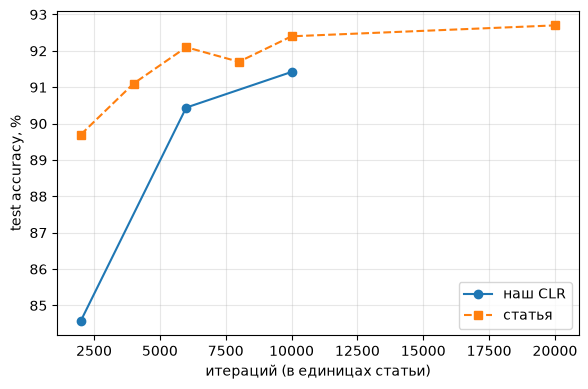

 ✓  Точность растёт с бюджетом
      статья: 89.7% (2k) → 92.7% (20k) | у нас: 84.6% → 91.4%, ранговая корреляция 1.00
 ✗  CLR за 6k итераций лучше PC за 80k
      статья: 92.1% против 91.2% | у нас: 90.4% против 91.6%


In [10]:
if 'budgets' in PLAN:
    ALL['budgets'] = {n: R(f'{n} итераций (статья)', s) for n, s in PLAN['budgets'].items()}
    ns = [n for n, rs in ALL['budgets'].items() if rs]
    a = [acc(ALL['budgets'][n]) for n in ns]
    plt.figure(figsize=(6, 4)); plt.plot(ns, a, 'o-', label='наш CLR')
    plt.plot([2000, 4000, 6000, 8000, 10000, 20000], [89.7, 91.1, 92.1, 91.7, 92.4, 92.7], 's--', label='статья')
    plt.xlabel('итераций (в единицах статьи)'); plt.ylabel('test accuracy, %'); plt.grid(alpha=.3); plt.legend()
    save('fig1b_budgets')
    rho = np.corrcoef(np.argsort(np.argsort(ns)), np.argsort(np.argsort(a)))[0, 1] if len(a) > 2 else float('nan')
    check('Точность растёт с бюджетом', '89.7% (2k) → 92.7% (20k)', f'{a[0]:.1f}% → {a[-1]:.1f}%, ранговая корреляция {rho:.2f}',
          '✓' if rho > 0.7 else '≈' if rho > 0 else '✗')
    if 'main' in ALL and 6000 in ALL['budgets']:
        pc = acc(ALL['main']['PC 0.35'], 'best_test')
        check('CLR за 6k итераций лучше PC за 80k', '92.1% против 91.2%', f'{acc(ALL["budgets"][6000]):.1f}% против {pc:.1f}%',
              verdict(acc(ALL['budgets'][6000]), pc))

## 4. Максимальный learning rate
**Гипотеза:** максимум LR около 3 работает лучше всего (0.1-3: 92.4%; 0.1-1: 91.3%).

   CLR 0.1-1.0                        test acc  89.99   [11.3 мин]
   CLR 0.1-3.0                        test acc  91.42   [11.3 мин]


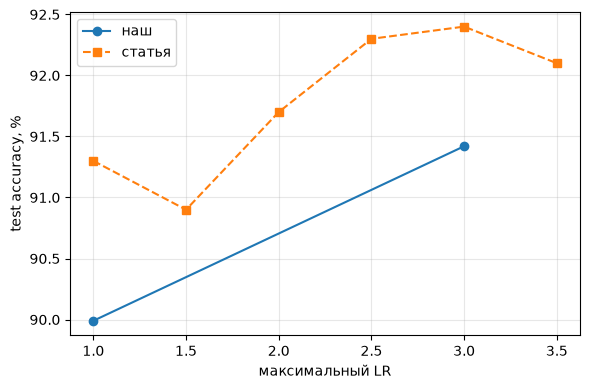

 ✓  Лучший максимальный LR около 3
      статья: лучше всего 2.5-3.5 | у нас: лучший 3.0, 1.0: 90.0%, 3.0: 91.4%


In [11]:
if 'max_lr' in PLAN:
    ALL['max_lr'] = {hi: R(f'CLR 0.1-{hi}', s) for hi, s in PLAN['max_lr'].items()}
    his = [h for h, rs in ALL['max_lr'].items() if rs]
    a = [acc(ALL['max_lr'][h]) for h in his]
    plt.figure(figsize=(6, 4)); plt.plot(his, a, 'o-', label='наш')
    plt.plot([1, 1.5, 2, 2.5, 3, 3.5], [91.3, 90.9, 91.7, 92.3, 92.4, 92.1], 's--', label='статья')
    plt.xlabel('максимальный LR'); plt.ylabel('test accuracy, %'); plt.grid(alpha=.3); plt.legend()
    save('table6_max_lr')
    best = his[int(np.argmax(a))]
    check('Лучший максимальный LR около 3', 'лучше всего 2.5-3.5', f'лучший {best}, '
          + ', '.join(f'{h}: {x:.1f}%' for h, x in zip(his, a)), '✓' if best >= 2.5 else '≈' if best >= 2 else '✗')

## 5. Оценка оптимального learning rate
**Гипотезы:** в первые 300 итераций оценка лежит примерно в диапазоне 2-6; при постоянном LR 0.1 оценка затем падает примерно до 0.2, а при CLR остаётся высокой (около 0.5 в конце). Малая кривизна означает широкие плоские минимумы.

   const 0.1                          test acc  86.54   [11.3 мин]
   CLR 0.1-3                          test acc  91.42   [11.3 мин]
   const 0.1, 300 it                  test acc  67.87   [1.2 мин]
   CLR 0.1-3, 300 it                  test acc  68.00   [1.2 мин]


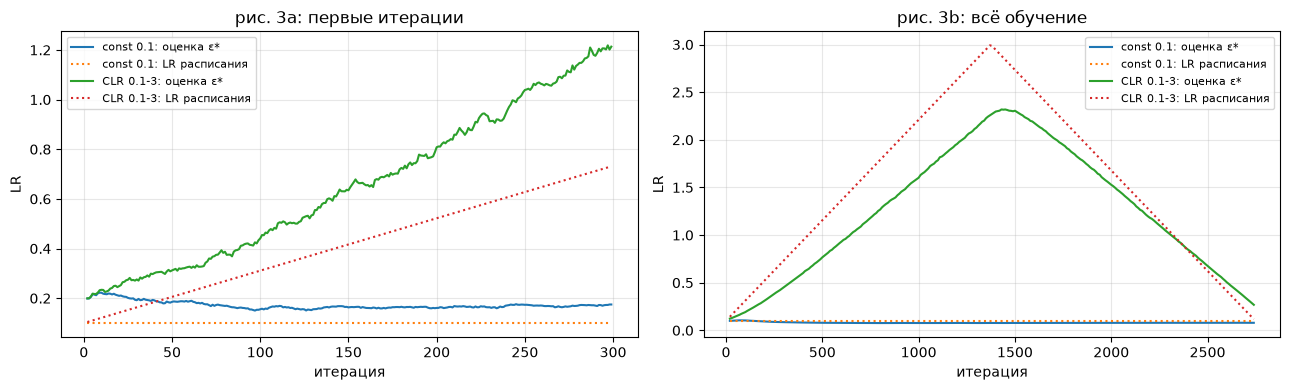

 ✗  Оценка ε* в начале обучения порядка 2-6
      статья: рис. 3a: 2-6 | у нас: медиана 0.81
 ✓  При CLR оценка в конце выше, чем при постоянном LR
      статья: рис. 3b: ~0.5 против ~0.2 | у нас: 0.73 против 0.08


In [12]:
if 'lr_estimate' in PLAN:
    ALL['lr_estimate'] = {l: R(l, s) for l, s in PLAN['lr_estimate'].items()}
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for a, suffix in zip(ax, [', 300 it', '']):
        for l in ['const 0.1', 'CLR 0.1-3']:
            rs = ALL['lr_estimate'][l + suffix]
            if rs and rs[0]['est']:
                e = np.array(rs[0]['est'])
                a.plot(e[:, 0], e[:, 1], label=f'{l}: оценка ε*')
                a.plot(e[:, 0], e[:, 2], ':', label=f'{l}: LR расписания')
        a.set(xlabel='итерация', ylabel='LR', title='рис. 3a: первые итерации' if suffix else 'рис. 3b: всё обучение'); a.grid(alpha=.3); a.legend(fontsize=8)
    save('fig3_lr_estimate')
    get = lambda l: np.array(ALL['lr_estimate'][l][0]['est']) if ALL['lr_estimate'][l] and ALL['lr_estimate'][l][0]['est'] else None
    e_c, e_s, e_short = get('const 0.1'), get('CLR 0.1-3'), get('CLR 0.1-3, 300 it')
    if e_short is not None:
        m = np.median(e_short[len(e_short) // 3:, 1])
        check('Оценка ε* в начале обучения порядка 2-6', 'рис. 3a: 2-6', f'медиана {m:.2f}', '✓' if 2 <= m <= 6 else '≈' if 1 <= m <= 10 else '✗')
    if e_c is not None and e_s is not None:
        tail_c, tail_s = e_c[-len(e_c) // 5:, 1].mean(), e_s[-len(e_s) // 5:, 1].mean()
        check('При CLR оценка в конце выше, чем при постоянном LR', 'рис. 3b: ~0.5 против ~0.2', f'{tail_s:.2f} против {tail_c:.2f}',
              '✓' if tail_s > tail_c else '✗')

## 6. Мало размеченных данных
**Гипотеза:** разрыв между CLR и PC растёт при уменьшении выборки (50k: +1.2, 20k: +5.2, 10k: +9.2 пункта).

   PC, 10k примеров                   test acc  82.25   [89.3 мин]
   CLR, 10k примеров                  test acc  85.21   [11.1 мин]
   PC, 50k примеров                   test acc  91.56   [90.4 мин]
   CLR, 50k примеров                  test acc  91.42   [11.3 мин]


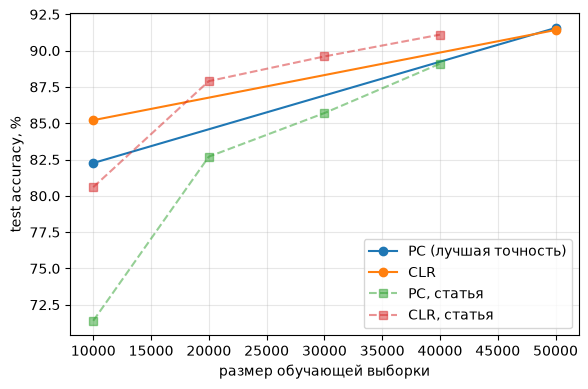

   разрыв CLR − PC: 10k: +2.9, 50k: -0.1
 ✓  Разрыв CLR − PC растёт при уменьшении данных
      статья: +1.2 (50k), +5.2 (20k), +9.2 (10k) | у нас: +2.9 (10k), -0.1 (50k)


In [13]:
if 'limited_data' in PLAN:
    ALL['limited_data'] = {k: R(f'{k[0]}, {k[1] // 1000}k примеров', s) for k, s in PLAN['limited_data'].items()}
    ns = sorted(LIMITED)
    pc = [acc(ALL['limited_data'][('PC', n)], 'best_test') for n in ns]
    sc = [acc(ALL['limited_data'][('CLR', n)]) for n in ns]
    plt.figure(figsize=(6, 4)); plt.plot(ns, pc, 'o-', label='PC (лучшая точность)'); plt.plot(ns, sc, 'o-', label='CLR')
    plt.plot([10000, 20000, 30000, 40000], [71.4, 82.7, 85.7, 89.1], 's--', alpha=.5, label='PC, статья')
    plt.plot([10000, 20000, 30000, 40000], [80.6, 87.9, 89.6, 91.1], 's--', alpha=.5, label='CLR, статья')
    plt.xlabel('размер обучающей выборки'); plt.ylabel('test accuracy, %'); plt.grid(alpha=.3); plt.legend()
    save('fig4a_limited_data')
    gaps = [s - p for s, p in zip(sc, pc)]
    print('   разрыв CLR − PC:', ', '.join(f'{n // 1000}k: {g:+.1f}' for n, g in zip(ns, gaps)))
    check('Разрыв CLR − PC растёт при уменьшении данных', '+1.2 (50k), +5.2 (20k), +9.2 (10k)',
          ', '.join(f'{g:+.1f} ({n // 1000}k)' for n, g in zip(ns, gaps)), verdict(gaps[0], gaps[-1] + 1, tol=1))

## 7. Глубина сети
**Гипотеза:** выигрыш больше для мелких сетей (ResNet-20: 90.4% против 88.6%; ResNet-110: 92.1% против 91.0%). Range test для них тоже показывает регуляризацию.

In [14]:
if 'depth' in PLAN:
    ALL['depth'] = {k: R(f'{k[0]} {k[1]}', s) for k, s in PLAN['depth'].items()}
    plot_rt({a: ALL['depth'][('RT', a)] for a in ['resnet20', 'resnet110']}, 'fig8b_range_test_depth')
    plot_curves({f'{p} {a}': ALL['depth'][(p, a)] for a in ['resnet20', 'resnet110'] for p in ['PC', 'CLR']}, 'fig4b_depth', 'ResNet-20 и ResNet-110')
    g = {}
    for a in ['resnet20', 'resnet110']:
        p, s = acc(ALL['depth'][('PC', a)], 'best_test'), acc(ALL['depth'][('CLR', a)])
        g[a] = s - p
        check(f'{a}: CLR не хуже PC', '90.4 vs 88.6' if a == 'resnet20' else '92.1 vs 91.0', f'{s:.1f}% против {p:.1f}%', verdict(s, p))
        if ALL['depth'][('RT', a)]:
            rt_checks(ALL['depth'][('RT', a)], a)
    check('Выигрыш у ResNet-20 больше, чем у ResNet-110', '+1.8 против +1.1', f"{g['resnet20']:+.1f} против {g['resnet110']:+.1f}",
          verdict(g['resnet20'], g['resnet110'], tol=0.3))

## 8. Размер батча
**Гипотезы:** при большем батче точность выше (256: 89.5%, 512: 91.7%, 1000: 92.4%, 1536: 92.1%); generalization gap (train − test) примерно одинаков для малого и большого батча.

In [15]:
if 'batch_size' in PLAN:
    ALL['batch_size'] = {bs: R(f'batch {bs}', s) for bs, s in PLAN['batch_size'].items()}
    bss = [b for b, rs in ALL['batch_size'].items() if rs]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(bss, [acc(ALL['batch_size'][b]) for b in bss], 'o-', label='наш')
    ax[0].plot([256, 512, 1000, 1536], [89.5, 91.7, 92.4, 92.1], 's--', label='статья')
    ax[0].set(xlabel='batch size', ylabel='test accuracy, %'); ax[0].legend()
    for b in bss:
        rs = ALL['batch_size'][b]
        x, tr = curve(rs, 'train_acc'); _, te = curve(rs, 'test_acc')
        ax[1].plot(x, tr - te, label=f'batch {b}')
    ax[1].set(xlabel='итерация', ylabel='train − test, п.п.', title='generalization gap'); ax[1].legend()
    for a in ax: a.grid(alpha=.3)
    save('fig5_batch_size')
    if 256 in bss and 1000 in bss:
        check('Большой батч лучше малого', '92.4% (1000) против 89.5% (256)',
              f'{acc(ALL["batch_size"][1000]):.1f}% против {acc(ALL["batch_size"][256]):.1f}%', verdict(acc(ALL['batch_size'][1000]), acc(ALL['batch_size'][256])))
        gap = lambda b: acc(ALL['batch_size'][b], 'final_train') - acc(ALL['batch_size'][b])
        d = abs(gap(1000) - gap(256))
        check('Generalization gap примерно одинаков', 'рис. 5b: «approximately equivalent»',
              f'gap {gap(256):.1f} (256) и {gap(1000):.1f} (1000) п.п.', '✓' if d < 1.5 else '≈' if d < 3 else '✗')

## 9. Momentum
**Гипотеза:** momentum слабо влияет (0.8: 92.1, 0.85: 91.9, 0.9: 92.4, 0.95: 90.7), 0.9 немного лучше. Циклический momentum (0.95→0.85) используется в табл. 2, здесь сравниваем его с постоянным.

In [16]:
if 'momentum' in PLAN:
    ALL['momentum'] = {m: R(f'momentum {m}', s) for m, s in PLAN['momentum'].items()}
    ms = [0.8, 0.85, 0.9, 0.95]
    a = [acc(ALL['momentum'][m]) for m in ms]
    plt.figure(figsize=(6, 4)); plt.plot(ms, a, 'o-', label='наш'); plt.plot(ms, [92.1, 91.9, 92.4, 90.7], 's--', label='статья')
    plt.axhline(acc(ALL['momentum']['0.95→0.85 (циклический)']), color='gray', ls=':', label='циклический 0.95→0.85')
    plt.xlabel('momentum'); plt.ylabel('test accuracy, %'); plt.grid(alpha=.3); plt.legend()
    save('table8_momentum')
    spread = np.nanmax(a) - np.nanmin(a)
    check('Momentum слабо влияет на результат', 'разброс 1.7 п.п., лучший 0.9', f'разброс {spread:.1f} п.п., лучший {ms[int(np.nanargmax(a))]}',
          '✓' if spread < 2 else '≈' if spread < 3 else '✗')

## 10. Weight decay
**Гипотеза:** weight decay 1e-3 мешает super-convergence, а 1e-4, 1e-5, 1e-6 нет; 1e-4 работает хорошо.

   weight decay 0.001                 test acc  10.00   [11.0 мин]
   weight decay 0.0001                test acc  91.42   [11.3 мин]
   weight decay 1e-05                 test acc  90.75   [11.0 мин]


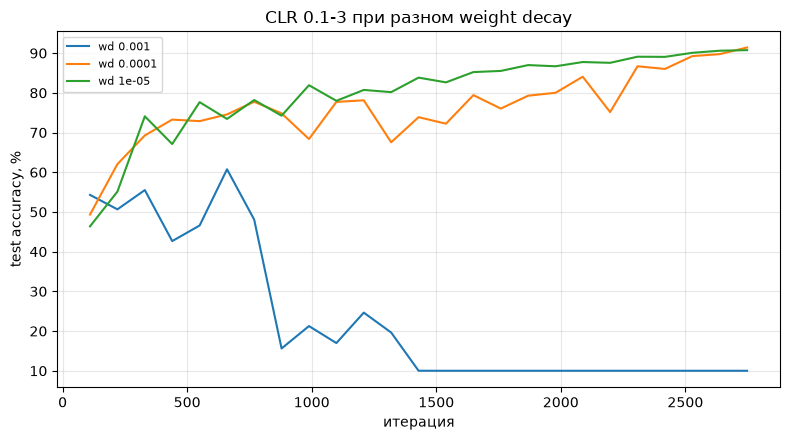

 ✓  Weight decay 1e-3 мешает super-convergence
      статья: рис. 12b: 1e-3 «prevents super-convergence» | у нас: 0.001: 10.0%, 0.0001: 91.4%, 1e-05: 90.8%


In [17]:
if 'weight_decay' in PLAN:
    ALL['weight_decay'] = {wd: R(f'weight decay {wd:g}', s) for wd, s in PLAN['weight_decay'].items()}
    plot_curves({f'wd {wd:g}': rs for wd, rs in ALL['weight_decay'].items()}, 'fig12b_weight_decay', 'CLR 0.1-3 при разном weight decay')
    a = {wd: acc(rs) for wd, rs in ALL['weight_decay'].items()}
    rest = min(a[w] for w in a if w < 1e-3)
    check('Weight decay 1e-3 мешает super-convergence', 'рис. 12b: 1e-3 «prevents super-convergence»',
          ', '.join(f'{w:g}: {x:.1f}%' for w, x in a.items()), '✓' if a[1e-3] < rest - 1 else '≈' if a[1e-3] < rest else '✗')

## 11. Статистики BatchNorm
**Гипотеза:** стандартный MAF = 0.999 мешает super-convergence (глобальные статистики не успевают обновиться), меньшие значения из табл. 6 работают.

   MAF 0.999                          test acc  15.90   [11.0 мин]
   MAF по табл. 6                     test acc  91.42   [11.3 мин]


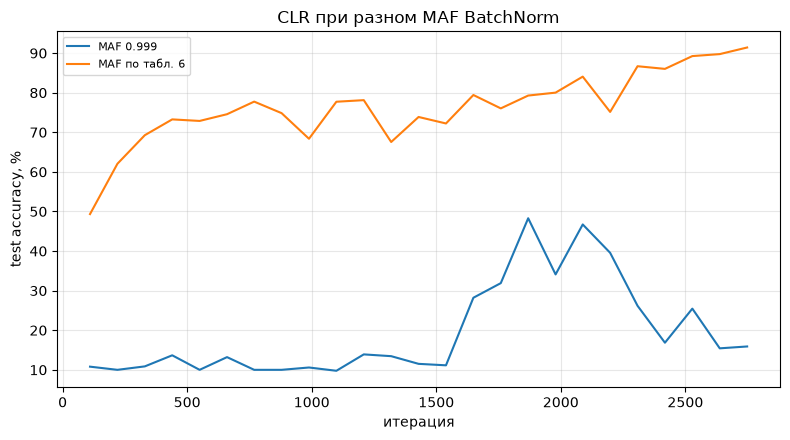

 ✓  MAF 0.999 мешает super-convergence
      статья: прил. A.5 | у нас: 15.9% (0.999) против 91.4% (табл. 6)


In [18]:
if 'bn_maf' in PLAN:
    ALL['bn_maf'] = {l: R(l, s) for l, s in PLAN['bn_maf'].items()}
    plot_curves(ALL['bn_maf'], 'a5_bn_maf', 'CLR при разном MAF BatchNorm')
    a, b = acc(ALL['bn_maf']['MAF 0.999']), acc(ALL['bn_maf']['MAF по табл. 6'])
    check('MAF 0.999 мешает super-convergence', 'прил. A.5', f'{a:.1f}% (0.999) против {b:.1f}% (табл. 6)', '✓' if a < b - 1 else '≈' if a < b else '✗')

## 12. Dropout
**Гипотеза:** с dropout 0.2 точность немного выше.

In [19]:
if 'dropout' in PLAN:
    ALL['dropout'] = {l: R(l, s) for l, s in PLAN['dropout'].items()}
    plot_rt({l: ALL['dropout'][l] for l in ['RT', 'RT + dropout 0.2']}, 'fig11a_dropout_rt')
    plot_curves({l: ALL['dropout'][l] for l in ['CLR', 'CLR + dropout 0.2']}, 'fig11b_dropout', 'CLR с dropout и без')
    a, b = acc(ALL['dropout']['CLR + dropout 0.2']), acc(ALL['dropout']['CLR'])
    check('С dropout 0.2 немного лучше', 'рис. 11b: «small improvement»', f'{a:.1f}% против {b:.1f}%', verdict(a, b, tol=0.3))

## 13. Адаптивные оптимизаторы
**Гипотезы:** при обычном расписании адаптивные методы не находят большие LR и не ускоряют обучение; с 1cycle super-convergence есть у Nesterov (92.1% за 10k против 90.9% за 80k), AdaDelta и AdaGrad, но не у Adam.

LR для AdaGrad, AdaDelta и Adam в статье не указаны. Здесь их выбирает range test: максимум CLR там, где точность максимальна, минимум в 30 раз меньше (как 0.1-3), LR для PC в 10 раз меньше максимума (как 0.35 для SGD). Это наш выбор, в отчёте его нужно оговорить.

In [20]:
def pick_max_lr(rs):
    h = rs[0]['hist']
    a = np.convolve(h['test_acc'], np.ones(5) / 5, mode='same')
    return float(h['lr'][int(np.argmax(a))])

if 'adaptive' in PLAN:
    ALL['adaptive'] = {}
    for o in ['nesterov', 'adagrad', 'adadelta', 'adam']:
        if o == 'nesterov':
            specs = {'PC': PLAN['adaptive'][('PC', o)], 'CLR': PLAN['adaptive'][('CLR', o)]}
        else:
            rt = R(f'RT {o}', PLAN['adaptive'][('RT', o)])
            if not rt:
                continue
            hi = pick_max_lr(rt)
            print(f'   {o}: максимальный LR по range test = {hi:.4g}')
            specs = {'PC': PC(opt=o, lr=hi / 10), 'CLR': CLR(opt=o, lo=hi / 30, hi=hi)}
        ALL['adaptive'][o] = {k: R(f'{k} {o}', s) for k, s in specs.items()}
    plot_curves({f'{k} {o}': rs for o, d in ALL['adaptive'].items() for k, rs in d.items()}, 'fig9_adaptive', 'Адаптивные методы: PC против 1cycle')
    for o, d in ALL['adaptive'].items():
        p, s = acc(d['PC'], 'best_test'), acc(d['CLR'])
        expected = o != 'adam'
        observed = s >= p - 0.5
        check(f'{o}: super-convergence ' + ('есть' if expected else 'нет'), '92.1 vs 90.9' if o == 'nesterov' else 'рис. 9',
              f'CLR {s:.1f}% против PC {p:.1f}%', '✓' if observed == expected else '✗')

## 14. SGDR
**Гипотеза:** с расписанием SGDR (косинус с рестартами) super-convergence не наблюдается.

In [21]:
if 'sgdr' in PLAN:
    ALL['sgdr'] = {l: R(l, s) for l, s in PLAN['sgdr'].items()}
    plot_curves(ALL['sgdr'], 'sec2_sgdr', 'SGDR против CLR (один бюджет и диапазон LR)')
    a, b = acc(ALL['sgdr']['SGDR 0.1-3']), acc(ALL['sgdr']['CLR 0.1-3'])
    check('С SGDR super-convergence нет (хуже CLR)', 'раздел 2', f'SGDR {a:.1f}% против CLR {b:.1f}%', '✓' if a < b - 0.5 else '≈' if a < b else '✗')

## 15. Другие датасеты и архитектуры
**Гипотезы:** на CIFAR-100 1cycle за 25 эпох лучше любого step-расписания (65.4% против ≤ 61.6%); на MNIST 1cycle за 12 эпох лучше step за 85 (99.25% против 99.00%); Wide ResNet: 1cycle за 50 эпох лучше step за 800 (91.3% против 90.3%); DenseNet: 1cycle за 150 эпох на уровне step за 400 (92.8% против 92.7%).

Baseline для CIFAR-100 в статье использует LR 0.005, что подозрительно мало. Поэтому добавлен step с LR 0.1, чтобы проверить, не слишком ли слабый baseline.

100.0%
100.0%
100.0%
100.0%


   step 0.01, 85 эп.                  test acc  98.92   [0.2 мин]
   1cycle 0.01-0.1, 12 эп.            test acc  98.82   [0.0 мин]
   1cycle 0.01-0.1, 25 эп.            test acc  99.05   [0.1 мин]
   1cycle 0.01-0.1, 50 эп.            test acc  99.14   [0.1 мин]
   1cycle 0.02-0.2, 85 эп.            test acc  99.29   [0.2 мин]


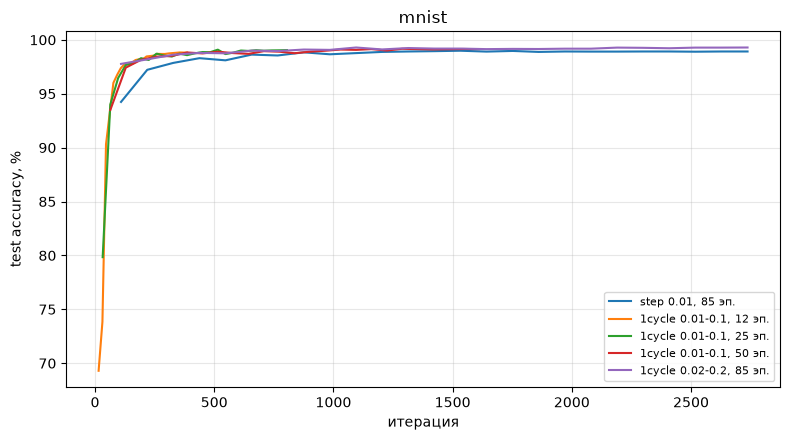

 ✗  MNIST: 1cycle за 12 эп. лучше step за 85
      статья: 99.25% против 99.00% | у нас: 98.82% против 98.99%


In [22]:
def table2(name, step_keys, cyc_key, paper, claim, tol=0.3):
    ALL[name] = {l: R(l, s) for l, s in PLAN[name].items()}
    plot_curves({l: rs for l, rs in ALL[name].items() if l != 'RT'}, f'table2_{name}', name)
    best_step = max(acc(ALL[name][k], 'best_test') for k in step_keys)
    c = acc(ALL[name][cyc_key])
    check(claim, paper, f'{c:.2f}% против {best_step:.2f}%', verdict(c, best_step, tol))

if 'cifar100' in PLAN:
    table2('cifar100', [f'step 0.005, {e} эп.' for e in [100, 200, 400]], '1cycle 0.1-0.5, 25 эп.', '65.4% против ≤ 61.6%',
           'CIFAR-100: 1cycle за 25 эп. лучше любого step 0.005')
    s01 = acc(ALL['cifar100']['step 0.1, 100 эп. (наша проверка baseline)'], 'best_test')
    check('CIFAR-100: 1cycle за 25 эп. лучше step 0.1 (наш, более сильный baseline)', 'нет в статье',
          f"{acc(ALL['cifar100']['1cycle 0.1-0.5, 25 эп.']):.2f}% против {s01:.2f}%", verdict(acc(ALL['cifar100']['1cycle 0.1-0.5, 25 эп.']), s01))
    if ALL['cifar100']['RT']:
        plot_rt({'CIFAR-100': ALL['cifar100']['RT']}, 'fig10a_cifar100_rt')
        rt_checks(ALL['cifar100']['RT'], 'CIFAR-100')
if 'mnist' in PLAN:
    table2('mnist', ['step 0.01, 85 эп.'], '1cycle 0.01-0.1, 12 эп.', '99.25% против 99.00%', 'MNIST: 1cycle за 12 эп. лучше step за 85', tol=0.05)
if 'wide_resnet' in PLAN:
    table2('wide_resnet', [f'step 0.1, {e} эп.' for e in [100, 200, 400, 800]], '1cycle 0.1-1.0, 50 эп.', '91.3% против 90.3%',
           'Wide ResNet: 1cycle за 50 эп. лучше step за 800')
if 'densenet' in PLAN:
    table2('densenet', ['step 0.1, 400 эп.'], '1cycle 0.1-4, 150 эп.', '92.8% против 92.7%', 'DenseNet: 1cycle за 150 эп. на уровне step за 400')

## Итог: что подтвердилось

In [23]:
lines = ['| Утверждение | Статья | У нас | Вердикт |', '|---|---|---|---|']
lines += [f'| {c} | {p} | {o} | {v} |' for c, (p, o, v) in CHECKS.items()]
table = '\n'.join(lines)
print(table)
open(f'{ROOT}/checks{"_debug" if DEBUG else ""}.md', 'w').write(table)
print('\nподтвердилось:', sum(v == '✓' for *_, v in CHECKS.values()), 'из', len(CHECKS))

| Утверждение | Статья | У нас | Вердикт |
|---|---|---|---|
| resnet20: точность высокая до LR = 3 | рис. 2b, «consistently high» | пик 80.5%, при LR ≥ 2.5: 75.1% | ≈ |
| resnet20: большой LR регуляризует (LR 0.3-1.5) | рис. 8: train loss ↑, test loss ↓ | наклон train loss -0.453, наклон (test − train) +0.057 | ✗ |
| Super-convergence: CLR (в 8 раз меньше итераций) не хуже PC | 92.4% против 91.2% | 91.4% против 91.6% | ≈ |
| 1cycle с хвостом лучше простого CLR | «allows an improvement in the accuracy» | 91.6% против 91.4% | ✓ |
| Точность растёт с бюджетом | 89.7% (2k) → 92.7% (20k) | 84.6% → 91.4%, ранговая корреляция 1.00 | ✓ |
| CLR за 6k итераций лучше PC за 80k | 92.1% против 91.2% | 90.4% против 91.6% | ✗ |
| Лучший максимальный LR около 3 | лучше всего 2.5-3.5 | лучший 3.0, 1.0: 90.0%, 3.0: 91.4% | ✓ |
| Оценка ε* в начале обучения порядка 2-6 | рис. 3a: 2-6 | медиана 0.81 | ✗ |
| При CLR оценка в конце выше, чем при постоянном LR | рис. 3b: ~0.5 против ~0.2 | 0.73 против 0.08 

UnicodeEncodeError: 'charmap' codec can't encode character '\u2265' in position 153: character maps to <undefined>

In [24]:
print('\nподтвердилось:', sum(v == '✓' for *_, v in CHECKS.values()), 'из', len(CHECKS))


подтвердилось: 7 из 13


допроверяем 3 и 4 гипотезы


   PC 0.35                            test acc  91.56   [90.4 мин]
   CLR 2000 итераций (статья)         test acc  84.58   [2.3 мин]
   CLR 6000 итераций (статья)         test acc  90.44   [6.8 мин]
   CLR 8000 итераций (статья)         test acc  91.02   [9.3 мин]
   CLR 10000 итераций (статья)        test acc  91.42   [11.3 мин]
   CLR 20000 итераций (статья)        test acc  91.81   [23.4 мин]


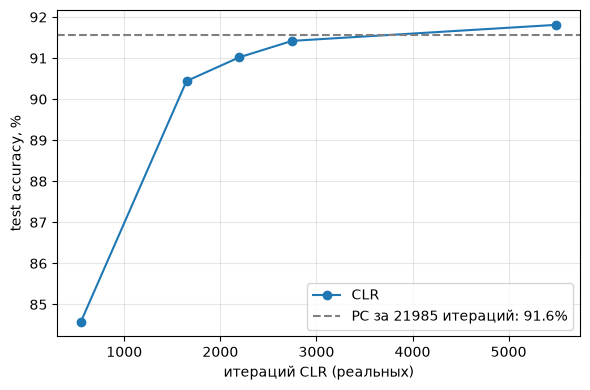

  2000 (549 итер., в 40.0 раза меньше PC): 84.58%  -> не догнал
  6000 (1648 итер., в 13.3 раза меньше PC): 90.44%  -> не догнал
  8000 (2198 итер., в 10.0 раза меньше PC): 91.02%  -> не догнал
 10000 (2748 итер., в 8.0 раза меньше PC): 91.42%  -> догнал PC
 20000 (5496 итер., в 4.0 раза меньше PC): 91.81%  -> догнал PC


In [25]:
assert it(10000) == 2748 and it(80000) == 21985, 'SCALE не совпадает с ночным прогоном: поставь SCALE = 0.274813'
pc = acc(R('PC 0.35', PC()), 'best_test')
bud = {n: R(f'CLR {n} итераций (статья)', CLR(iters=n)) for n in [2000, 6000, 8000, 10000, 20000]}
ns = list(bud); a = [acc(bud[n]) for n in ns]

plt.figure(figsize=(6, 4))
plt.plot([it(n) for n in ns], a, 'o-', label='CLR')
plt.axhline(pc, color='gray', ls='--', label=f'PC за {it(80000)} итераций: {pc:.1f}%')
plt.xlabel('итераций CLR (реальных)'); plt.ylabel('test accuracy, %'); plt.grid(alpha=.3); plt.legend()
save('h3_budget_vs_pc')
for n, x in zip(ns, a):
    print(f'{n:6d} ({it(n)} итер., в {it(80000) / it(n):.1f} раза меньше PC): {x:.2f}%  ->',
          'догнал PC' if x >= pc - 0.2 else 'не догнал')

In [26]:
gap = lambda rs: acc(rs, 'final_train') - acc(rs, 'final_test')
for name, spec in {'CLR, макс. LR 1': CLR(hi=1.0), 'CLR, макс. LR 3': CLR(), 'PC 0.35': PC()}.items():
    rs = R(name, spec)
    print(f'      train {acc(rs, "final_train"):.2f}%, разрыв train − test: {gap(rs):.2f} п.')


   CLR, макс. LR 1                    test acc  89.99   [11.3 мин]
      train 97.48%, разрыв train − test: 7.49 п.
   CLR, макс. LR 3                    test acc  91.42   [11.3 мин]
      train 97.54%, разрыв train − test: 6.12 п.
   PC 0.35                            test acc  91.56   [90.4 мин]
      train 99.99%, разрыв train − test: 8.43 п.


   range test                         test acc  74.73   [5.9 мин]
   контроль: const LR 0.1             test acc  85.40   [5.9 мин]


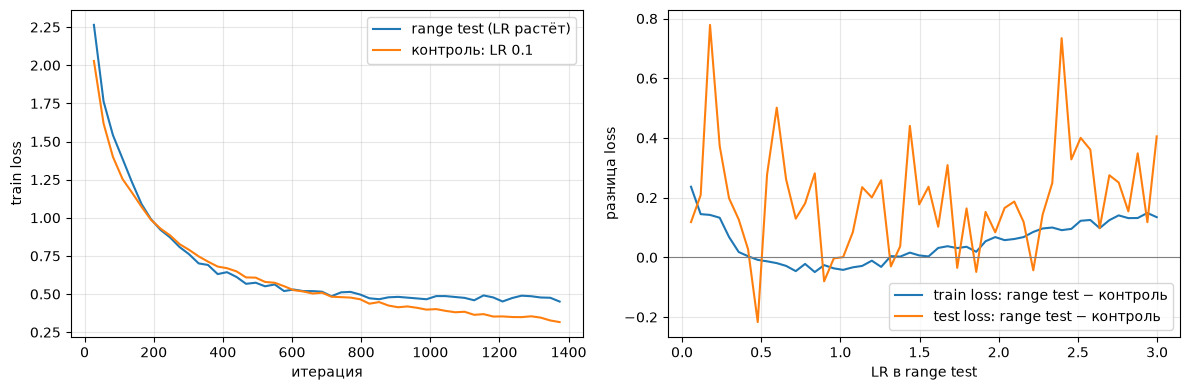

наклон разницы train loss: 0.006 (> 0 значит регуляризация)
наклон разницы test loss:  0.051


In [27]:
rt = R('range test', RT())
ctrl = R('контроль: const LR 0.1', {**RT(), 'policy': dict(kind='const', lr=0.1)})
h, c = rt[0]['hist'], ctrl[0]['hist']
lr = np.array(h['lr'])
d_tr = np.array(h['train_loss']) - np.array(c['train_loss'])
d_te = np.array(h['test_loss']) - np.array(c['test_loss'])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h['it'], h['train_loss'], label='range test (LR растёт)')
ax[0].plot(c['it'], c['train_loss'], label='контроль: LR 0.1')
ax[0].set(xlabel='итерация', ylabel='train loss'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(lr, d_tr, label='train loss: range test − контроль')
ax[1].plot(lr, d_te, label='test loss: range test − контроль')
ax[1].axhline(0, color='gray', lw=.8)
ax[1].set(xlabel='LR в range test', ylabel='разница loss'); ax[1].legend(); ax[1].grid(alpha=.3)
save('h4_control_resnet20')
m = (lr >= 0.3) & (lr <= 1.5)
print('наклон разницы train loss:', round(np.polyfit(lr[m], d_tr[m], 1)[0], 3), '(> 0 значит регуляризация)')
print('наклон разницы test loss: ', round(np.polyfit(lr[m], d_te[m], 1)[0], 3))